<a href="https://colab.research.google.com/github/lkundrap-max/FDS-7140/blob/main/online_purchase_analysis_CS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape after cleaning: (12205, 18)
Remaining duplicates: 0
Missing values: 0

 Logistic Regression
Selected threshold: 0.5851
Validation F1: 0.4147

Classification report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.74      0.81      2059
    Purchase       0.29      0.57      0.39       382

    accuracy                           0.72      2441
   macro avg       0.60      0.66      0.60      2441
weighted avg       0.81      0.72      0.75      2441

Confusion matrix:
[[1528  531]
 [ 164  218]]


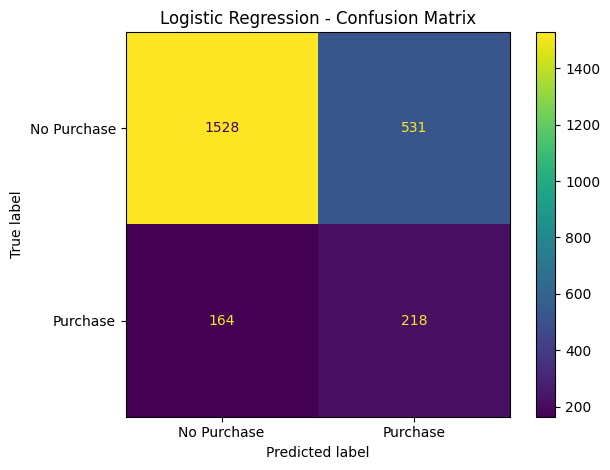


 Random Forest
Selected threshold: 0.245
Validation F1: 0.4072

Classification report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.82      0.86      2059
    Purchase       0.34      0.48      0.40       382

    accuracy                           0.77      2441
   macro avg       0.62      0.65      0.63      2441
weighted avg       0.81      0.77      0.79      2441

Confusion matrix:
[[1696  363]
 [ 198  184]]


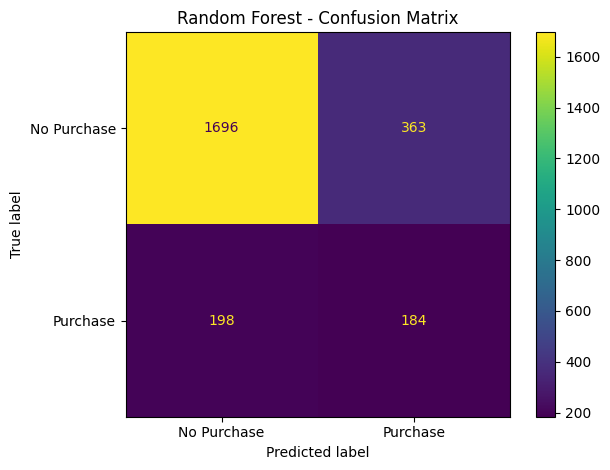


FINAL MODEL COMPARISON
              Model  Threshold  Accuracy  Purchase Precision  Purchase Recall  Purchase F1  ROC-AUC  Average Precision
Logistic Regression     0.5851    0.7153              0.2911           0.5707       0.3855   0.7306             0.3356
      Random Forest     0.2450    0.7702              0.3364           0.4817       0.3961   0.7568             0.3324


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    precision_recall_curve, ConfusionMatrixDisplay
)

# 1. Load and clean dataset
df = pd.read_csv(
    "/content/online_shoppers_intention.csv"
)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

# 2. Separate features and target
X = df.drop(columns=["Revenue", "PageValues"])
y = df["Revenue"].astype(int)

categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

# 3. Split data into training, validation and test sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40,
    random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

# 4. Preprocess numerical and categorical features
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# 5. Define both models
classifiers = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []

# 6. Train, tune thresholds and evaluate
for name, classifier in classifiers.items():

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    # Tune threshold using validation data
    val_prob = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, val_prob
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_values)
    best_threshold = thresholds[best_idx]

    # Evaluate on the same test set
    test_prob = model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)

    results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Purchase Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Purchase Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "Purchase F1": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, test_prob),
        "Average Precision": average_precision_score(
            y_test, test_prob
        )
    })

    print("\n", name)
    print("Selected threshold:", round(best_threshold, 4))
    print("Validation F1:", round(f1_values[best_idx], 4))
    print("\nClassification report:")
    print(classification_report(
        y_test, test_pred,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_test, test_pred))

    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred,
        display_labels=["No Purchase", "Purchase"],
        values_format="d"
    )
    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()

# 7. Compare both models
comparison = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(comparison.round(4).to_string(index=False))
